<a href="https://colab.research.google.com/github/emrizky1/PCVK_Ganjil_2026/blob/main/week6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

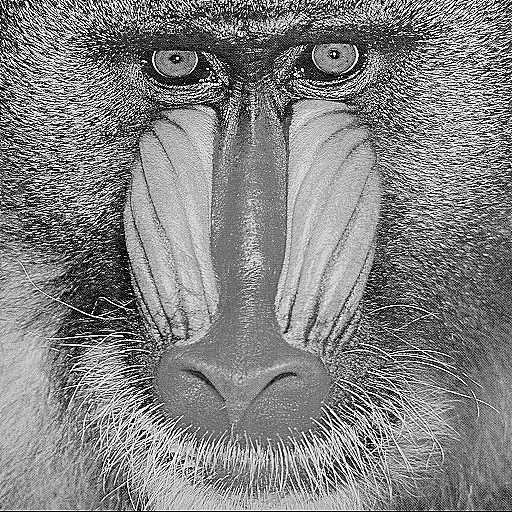

In [ ]:
img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
kernel_sharpen = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
img_sharp = cv.filter2D(img_gray, -1, kernel_sharpen)
cv2_imshow(img_sharp)

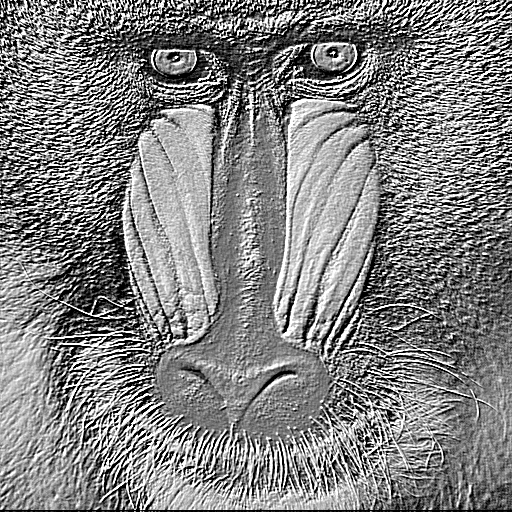

In [ ]:
img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
kernel_emboss = np.array([[-2,-1,0],[-1,1,1],[0,1,2]])
img_emboss = cv.filter2D(img_gray, -1, kernel_emboss)
cv2_imshow(img_emboss)

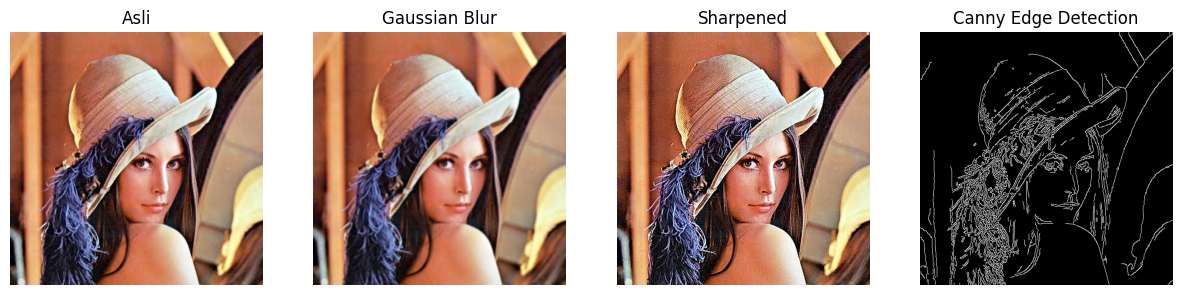

In [ ]:
def show_side_by_side(images, titles, figsize=(15,5)):
  plt.figure(figsize=figsize)
  for i, (img, title) in enumerate(zip(images, titles)):
    if len(img.shape) == 2:
      plt.subplot(1, len(images), i+1)
      plt.imshow(img, cmap="gray")
    else:
      plt.subplot(1, len(images), i+1)
      plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
  plt.show()

img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/lena.jpg')
img_gray = (cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)

blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges], ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

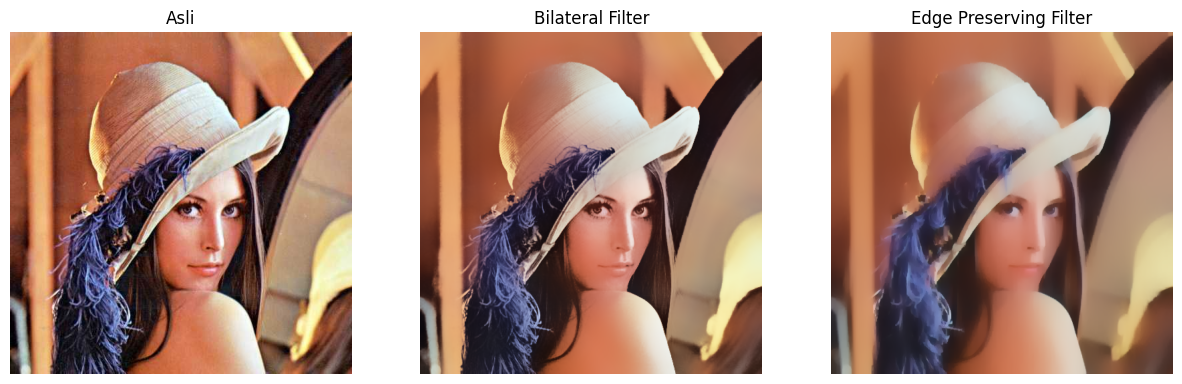

In [ ]:
def show_side_by_side(images, titles, figsize=(15,5)):
  plt.figure(figsize=figsize)
  for i, (img, title) in enumerate(zip(images, titles)):
    if len(img.shape) == 2:
      plt.subplot(1, len(images), i+1)
      plt.imshow(img, cmap="gray")
    else:
      plt.subplot(1, len(images), i+1)
      plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
  plt.show()

bilateral = cv.bilateralFilter(img, 50, 100, 100)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve], ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

<class 'numpy.ndarray'>
(512, 512)


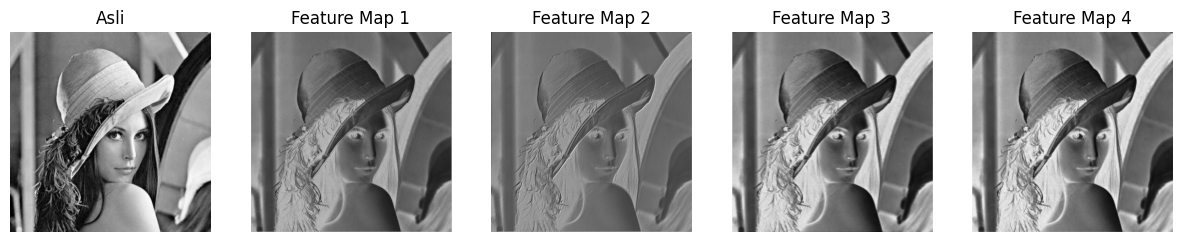

In [ ]:
img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

print(type(img_gray))
print(img_gray.shape)

import torch
import torch.nn as nn

def show_side_by_side(images, titles, figsize=(15,5)):
  plt.figure(figsize=figsize)
  for i, (img, title) in enumerate(zip(images, titles)):
    if len(img.shape) == 2:
      plt.subplot(1, len(images), i+1)
      plt.imshow(img, cmap="gray")
    else:
      plt.subplot(1, len(images), i+1)
      plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
  plt.show()

class SimpleCNN(nn.Module):
  def __init__(self):
    super(SimpleCNN, self).__init__()
    self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

  def forward(self, x):
    return self.conv1(x)

model = SimpleCNN()

img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

with torch.no_grad():
  features = model(img_tensor)

feature_maps = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli"] + [f"Feature Map {i+1}" for i in range(len(feature_maps))])

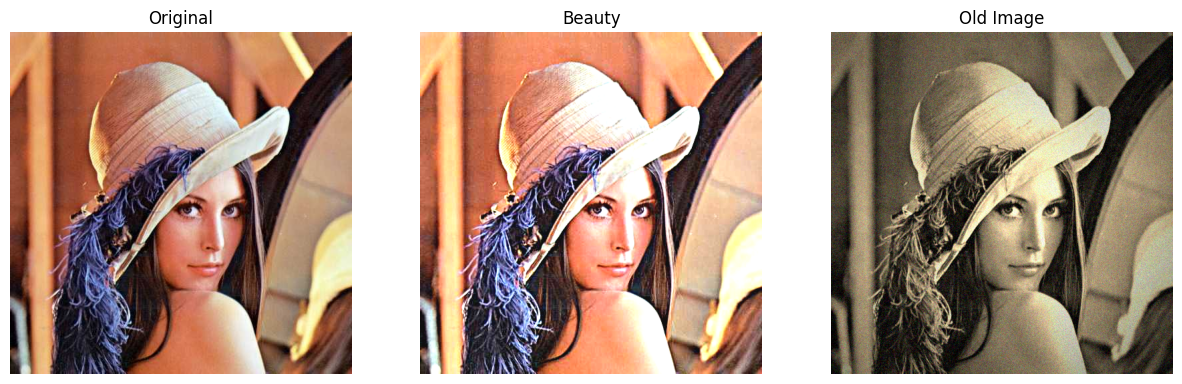

In [ ]:
img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/lena.jpg')

smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(img, 1.5, gaussian, -0.5, 0)

alpha = 1.2
beta = 15
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

sepia_kernel = np.array([[0.272, 0.534, 0.131], [0.349, 0.686, 0.168], [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
  vignette[:, :, i] = vignette[:, :, i] * mask

noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img], ["Original", "Beauty", "Old Image"])

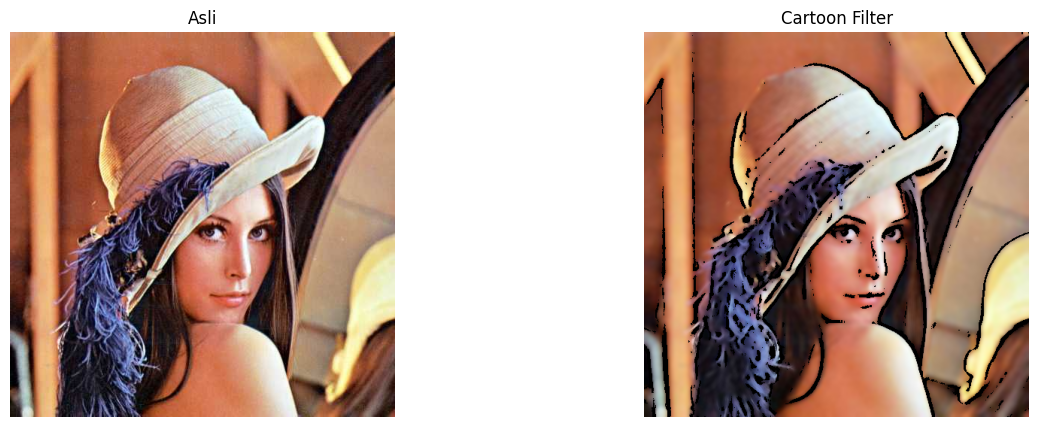

In [ ]:
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)

color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)
cartoon = cv.bitwise_and(color, color, mask=edges)

show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

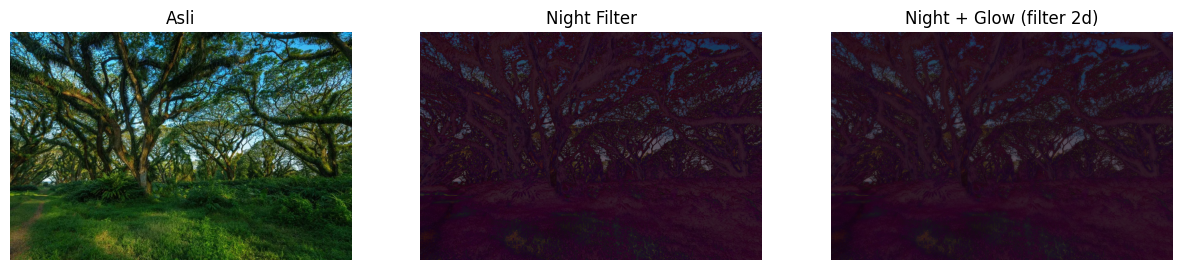

In [ ]:
img = cv.imread("/content/drive/MyDrive/pcvk_2026/Images/djawatan.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

blue_tint = np.full_like(night, (50, 0, 100))
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

kernel = np.ones((15,15), np.float32) / 255
glow = cv.filter2D(night, -1, kernel)

night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow], ["Asli", "Night Filter", "Night + Glow (filter 2d)"])

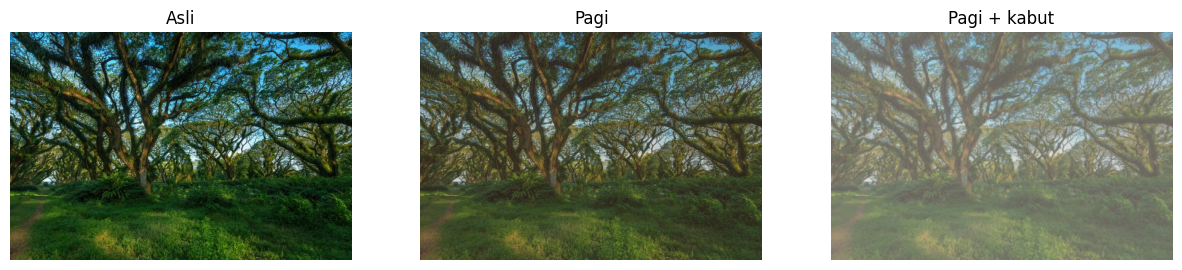

In [ ]:
alpha = 0.9
beta = 20
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

warm_tint = np.full_like(soft, (40, 70, 120))
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T
kabut = cv.filter2D(pagi, -1, kernel)

white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut], ["Asli", "Pagi", "Pagi + kabut"])

---
## 1

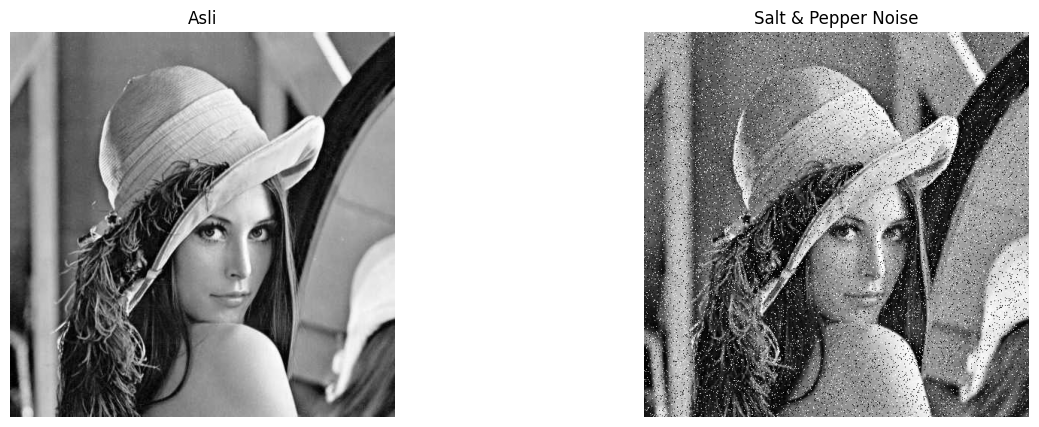

In [ ]:
img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/lena.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

def salt_pepper_noise(image, amount=0.05):
  noisy = image.copy()

  num_pixels = int(amount * image.size)

  coords = (
      np.random.randint(0, image.shape[0], num_pixels),
      np.random.randint(0, image.shape[1], num_pixels)
  )
  noisy[coords] = 255

  coords = (
      np.random.randint(0, image.shape[0], num_pixels),
      np.random.randint(0, image.shape[1], num_pixels)
  )
  noisy[coords] = 0

  return noisy

img_noisy = salt_pepper_noise(gray)
show_side_by_side([gray, img_noisy], ["Asli", "Salt & Pepper Noise"])
#

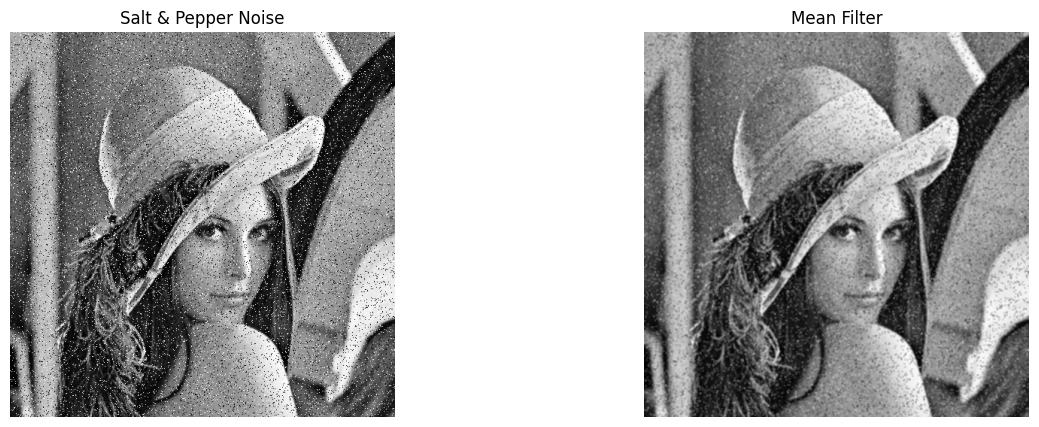

In [ ]:
mean_kernel = np.ones((3,3), dtype=np.float32) / 9

mean_result = cv.filter2D(img_noisy, -1, mean_kernel)
cv.filter2D(img_noisy, -1, mean_kernel)
show_side_by_side([img_noisy, mean_result], ["Salt & Pepper Noise", "Mean Filter"])
#

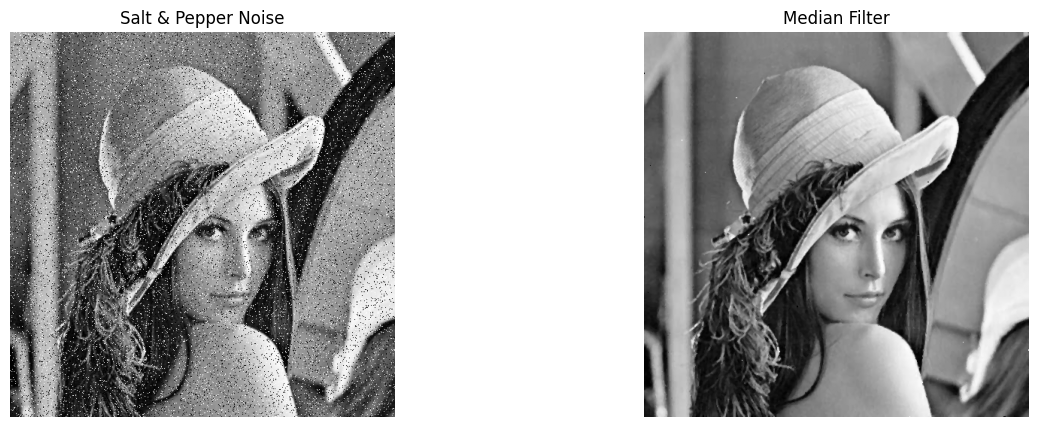

In [ ]:
median_result = cv.medianBlur(img_noisy, 3)

show_side_by_side([img_noisy, median_result], ["Salt & Pepper Noise", "Median Filter"])

---
## 2

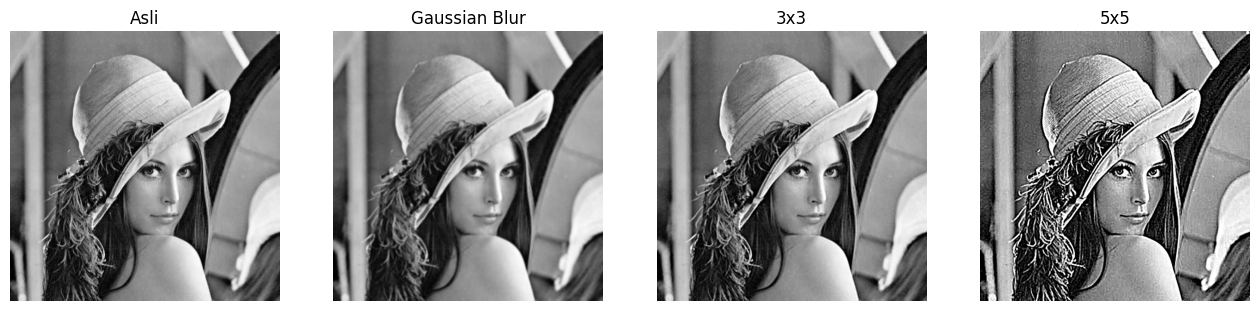

In [ ]:
kernel_3x3 = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
kernel_5x5 = np.array([[0,0,-1,0,0],[0,-1,-1,-1,0],[-1,-1,13,-1,-1],[0,-1,-1,-1,0],[0,0,-1,0,0]])

img_blur = cv.GaussianBlur(gray, (5,5), 1)

sharp_3x3 = cv.filter2D(img_blur, -1, kernel_3x3)
sharp_5x5 = cv.filter2D(img_blur, -1, kernel_5x5)

show_side_by_side([gray, img_blur, sharp_3x3, sharp_5x5], ["Asli", "Gaussian Blur", "3x3", "5x5"], figsize=(16,5))
#

---
## 3

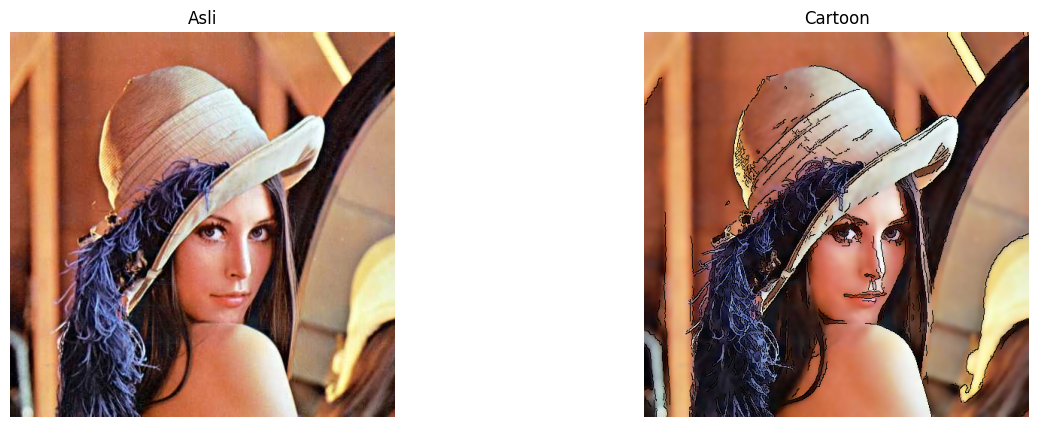

In [ ]:
def kartun(image):
  smooth = cv.bilateralFilter(image, 9, 75, 75)
  gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
  edges = cv.Canny(gray, 100, 200)
  edges = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
  edges = 255 - edges
  cartoon = cv.bitwise_and(smooth, edges)

  return cartoon

img = cv.imread('/content/drive/MyDrive/pcvk_2026/Images/lena.jpg')

result_cartoon = kartun(img)
show_side_by_side([img, result_cartoon], ["Asli", "Cartoon"])